# Data Cleaning and Data Analysis

### Data Cleaning

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.ticker import MaxNLocator

In [3]:
df = pd.read_csv('cars_scraped.csv')

In [4]:
df

,Car Name,Brand Name,Model Name,KM Driven,Transmission Type,Price,Fuel Type,Year,Cities name,Owner Type
0,2016 Maruti Swift,Maruti,Swift,"65,394 km",Manual,₹3.04 lakh,Petrol,2016,delhi-ncr,1st
1,2022 Maruti Celerio,Maruti,Celerio,"34,195 km",Manual,NaN,Petrol,2022,delhi-ncr,1st
2,2023 Maruti Swift,Maruti,Swift,"17,659 km",Manual,₹5.71 lakh,Petrol,2023,delhi-ncr,1st
3,2022 Maruti New Wagon-R,Maruti,New Wagon-R,"28,476 km",Manual,NaN,Petrol,2022,delhi-ncr,1st
4,2018 Maruti Baleno,Maruti,Baleno,"49,673 km",Manual,NaN,Petrol,2018,delhi-ncr,1st
...,...,...,...,...,...,...,...,...,...,...
3631,2012 Audi A6,Audi,A6,"1,13,840 km",Auto,₹3.80 lakh,Diesel,2012,agra,2nd
3632,2012 Audi Q5,Audi,Q5,"1,81,601 km",Auto,₹5.10 lakh,Diesel,2012,agra,2nd
3633,2012 Audi A6,Audi,A6,"1,05,129 km",Auto,₹6.00 lakh,Diesel,2012,bhopal,2nd
3634,2014 Audi Q3,Audi,Q3,"1,82,910 km",Auto,NaN,Diesel,2014,rajkot,3rd


In [6]:
# Handle missing values
df.isnull().sum()

Car Name                0
Brand Name              0
Model Name              0
KM Driven               0
Transmission Type       0
Price                1275
Fuel Type               0
Year                    0
Cities name             0
Owner Type              0
dtype: int64

In [7]:
# Remove currency symbols
df['Price'] = df['Price'].str.replace('lakh','')
df['Price'] = df['Price'].str.replace('₹','')

In [8]:
# Convert price into numeric
df['Price'] = df['Price'].astype(float)

In [9]:
df['Price'] = df['Price']*100000

In [10]:
price_data = df.dropna(subset=['Price'])

In [11]:
average_price_by_city = price_data.groupby('Cities name')['Price'].mean()

In [12]:
price_data.isnull().sum()

Car Name             0
Brand Name           0
Model Name           0
KM Driven            0
Transmission Type    0
Price                0
Fuel Type            0
Year                 0
Cities name          0
Owner Type           0
dtype: int64

In [13]:
df['KM Driven']

0         65,394 km
1         34,195 km
2         17,659 km
3         28,476 km
4         49,673 km
           ...     
3631    1,13,840 km
3632    1,81,601 km
3633    1,05,129 km
3634    1,82,910 km
3635    2,08,245 km
Name: KM Driven, Length: 3636, dtype: object

In [14]:
# Convert kilometres into integers
df['KM Driven'] = df['KM Driven'].str.replace('km','')
df['KM Driven'] = df['KM Driven'].str.replace(',','')
df['KM Driven'] = df['KM Driven'].astype('int64')

In [15]:
# Remove duplicates
cars = df.drop_duplicates()
cars.nunique()
cars.duplicated().sum()

np.int64(0)

#### Checking outliers

In [16]:
# Checking outliers for 'Price'
Q1 = price_data['Price'].quantile(0.25)
Q3 = price_data['Price'].quantile(0.75)

IQR = Q3-Q1

lower_limit = Q1 - 1.5 * IQR
upper_limit = Q3 + 1.5 * IQR

outliers = price_data[
    (price_data['Price'] < lower_limit) |
    (price_data['Price'] > upper_limit)
]

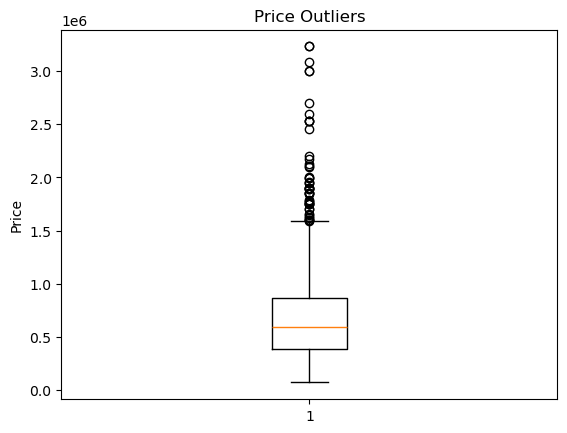

In [17]:
plt.boxplot(price_data['Price'])
plt.title('Price Outliers')
plt.ylabel('Price')
plt.show()

#### Conclusions:
> + Price: Outliers were found, but they represent genuine high-priced cars, so they were retained.

In [18]:
# Checking outliers for 'KM Driven'
Q1 = cars['KM Driven'].quantile(0.25)
Q3 = cars['KM Driven'].quantile(0.75)

IQR = Q3-Q1

lower_limit = Q1 - 1.5 * IQR
upper_limit = Q3 + 1.5 * IQR

outliers = cars[(cars['KM Driven']<lower_limit) | (cars['KM Driven']>upper_limit)]

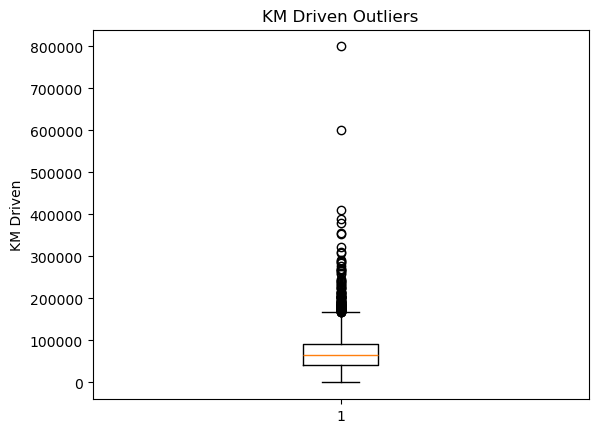

In [19]:
plt.boxplot(cars['KM Driven'])
plt.title('KM Driven Outliers')
plt.ylabel('KM Driven')
plt.show()

#### Conclusion: 
> + `KM Driven`: Outliers were found, but they represent genuine variations in mileage, so they were retained.

In [20]:
df.dtypes

Car Name              object
Brand Name            object
Model Name            object
KM Driven              int64
Transmission Type     object
Price                float64
Fuel Type             object
Year                   int64
Cities name           object
Owner Type            object
dtype: object

In [22]:
df

,Car Name,Brand Name,Model Name,KM Driven,Transmission Type,Price,Fuel Type,Year,Cities name,Owner Type
0,2016 Maruti Swift,Maruti,Swift,65394,Manual,304000.0,Petrol,2016,delhi-ncr,1st
1,2022 Maruti Celerio,Maruti,Celerio,34195,Manual,NaN,Petrol,2022,delhi-ncr,1st
2,2023 Maruti Swift,Maruti,Swift,17659,Manual,571000.0,Petrol,2023,delhi-ncr,1st
3,2022 Maruti New Wagon-R,Maruti,New Wagon-R,28476,Manual,NaN,Petrol,2022,delhi-ncr,1st
4,2018 Maruti Baleno,Maruti,Baleno,49673,Manual,NaN,Petrol,2018,delhi-ncr,1st
...,...,...,...,...,...,...,...,...,...,...
3631,2012 Audi A6,Audi,A6,113840,Auto,380000.0,Diesel,2012,agra,2nd
3632,2012 Audi Q5,Audi,Q5,181601,Auto,510000.0,Diesel,2012,agra,2nd
3633,2012 Audi A6,Audi,A6,105129,Auto,600000.0,Diesel,2012,bhopal,2nd
3634,2014 Audi Q3,Audi,Q3,182910,Auto,NaN,Diesel,2014,rajkot,3rd


In [23]:
# Cleaned data 
df.to_csv('cleaned_data.csv', index=False)

In [24]:
df

,Car Name,Brand Name,Model Name,KM Driven,Transmission Type,Price,Fuel Type,Year,Cities name,Owner Type
0,2016 Maruti Swift,Maruti,Swift,65394,Manual,304000.0,Petrol,2016,delhi-ncr,1st
1,2022 Maruti Celerio,Maruti,Celerio,34195,Manual,NaN,Petrol,2022,delhi-ncr,1st
2,2023 Maruti Swift,Maruti,Swift,17659,Manual,571000.0,Petrol,2023,delhi-ncr,1st
3,2022 Maruti New Wagon-R,Maruti,New Wagon-R,28476,Manual,NaN,Petrol,2022,delhi-ncr,1st
4,2018 Maruti Baleno,Maruti,Baleno,49673,Manual,NaN,Petrol,2018,delhi-ncr,1st
...,...,...,...,...,...,...,...,...,...,...
3631,2012 Audi A6,Audi,A6,113840,Auto,380000.0,Diesel,2012,agra,2nd
3632,2012 Audi Q5,Audi,Q5,181601,Auto,510000.0,Diesel,2012,agra,2nd
3633,2012 Audi A6,Audi,A6,105129,Auto,600000.0,Diesel,2012,bhopal,2nd
3634,2014 Audi Q3,Audi,Q3,182910,Auto,NaN,Diesel,2014,rajkot,3rd


In [25]:
df = pd.read_csv('cleaned_data.csv')

In [26]:
df

,Car Name,Brand Name,Model Name,KM Driven,Transmission Type,Price,Fuel Type,Year,Cities name,Owner Type
0,2016 Maruti Swift,Maruti,Swift,65394,Manual,304000.0,Petrol,2016,delhi-ncr,1st
1,2022 Maruti Celerio,Maruti,Celerio,34195,Manual,NaN,Petrol,2022,delhi-ncr,1st
2,2023 Maruti Swift,Maruti,Swift,17659,Manual,571000.0,Petrol,2023,delhi-ncr,1st
3,2022 Maruti New Wagon-R,Maruti,New Wagon-R,28476,Manual,NaN,Petrol,2022,delhi-ncr,1st
4,2018 Maruti Baleno,Maruti,Baleno,49673,Manual,NaN,Petrol,2018,delhi-ncr,1st
...,...,...,...,...,...,...,...,...,...,...
3631,2012 Audi A6,Audi,A6,113840,Auto,380000.0,Diesel,2012,agra,2nd
3632,2012 Audi Q5,Audi,Q5,181601,Auto,510000.0,Diesel,2012,agra,2nd
3633,2012 Audi A6,Audi,A6,105129,Auto,600000.0,Diesel,2012,bhopal,2nd
3634,2014 Audi Q3,Audi,Q3,182910,Auto,NaN,Diesel,2014,rajkot,3rd


### Average price by city (Bivariate Analysis)

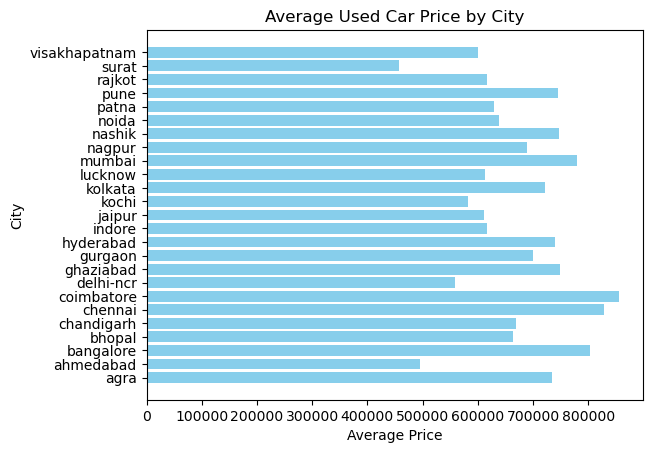

In [33]:
# Average price by city & City-wise price comparison
average_price_by_city = price_data.groupby('Cities name')['Price'].mean()

plt.barh(average_price_by_city.index,average_price_by_city.values,color= 'skyblue')

plt.xlabel('Average Price')
plt.ylabel('City')
plt.title('Average Used Car Price by City')
plt.show()

#### Conclusion: 
> + Coimbatore has the highest average used-car price, whereas Surat has the lowest average used-car price among the cities analyzed.

### Average price by brand (Bivariate Analysis)

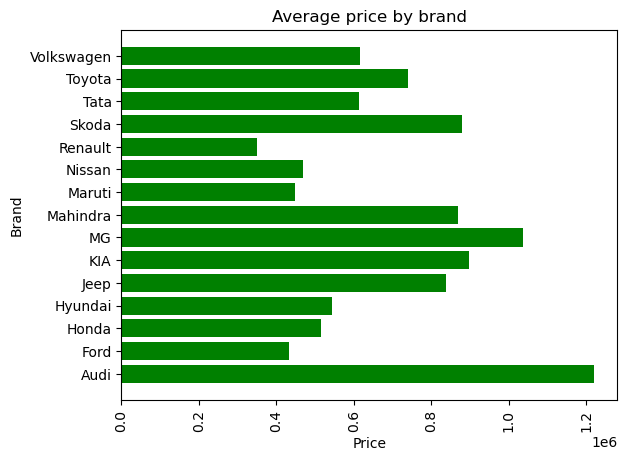

In [34]:
# Average price by brand
average_price_by_brand = cars.groupby('Brand Name')['Price'].mean()
# Graph
plt.barh(average_price_by_brand.index,average_price_by_brand.values,color= 'green')
plt.xlabel('Price')
plt.ylabel('Brand')
plt.title('Average price by brand')
plt.xticks(rotation=90)
plt.show()

#### Conclusion: 
> + Audi has the highest average used-car price, whereas Renualt has the lowest average used-car price.

### Fuel type comparison (Univariate Analysis)

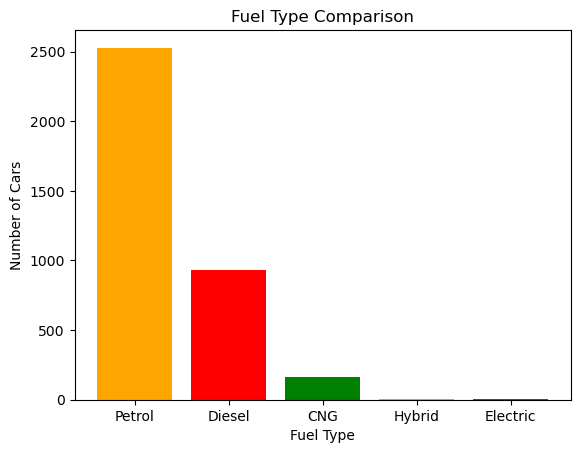

In [37]:
fuel_type_counts = cars['Fuel Type'].value_counts()

plt.bar(fuel_type_counts.index, fuel_type_counts.values,color=['Orange','Red','Green'])

plt.xlabel('Fuel Type')
plt.ylabel('Number of Cars')
plt.title('Fuel Type Comparison')

plt.show()

#### Conclusion:
> + Petrol cars have the highest number of listings, whereas electric cars and Hybrid cars have the lowest number of listings.

### Manual vs Automatic (Univariate analysis)

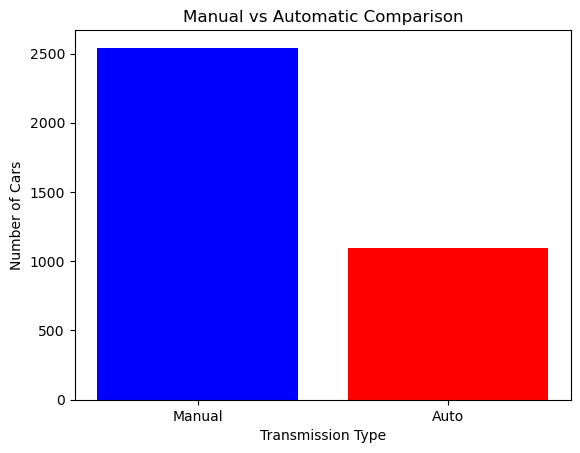

In [39]:
# Manual vs Automatic
transmission_type_counts = cars['Transmission Type'].value_counts()

plt.bar(transmission_type_counts.index, transmission_type_counts.values,color=['Blue','Red'])

plt.xlabel('Transmission Type')
plt.ylabel('Number of Cars')
plt.title('Manual vs Automatic Comparison')

plt.show()

#### Conclusion:
> + Manual cars have the highest number of listings, whereas Automatic cars have the lowest number of listings.

### Owner type distribution

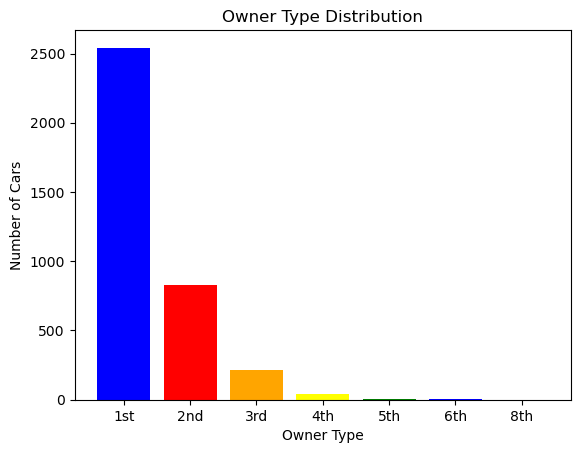

In [41]:
# Owner type distribution
owner_type_counts = cars['Owner Type'].value_counts()

plt.bar(owner_type_counts.index, owner_type_counts.values,color=['Blue','Red','Orange','Yellow','Green'])
plt.xlabel('Owner Type')
plt.ylabel('Number of Cars')
plt.title('Owner Type Distribution')
plt.show()

#### Conclusion:
> + 1st-owner cars have the highest number of listings, whereas 5th-owner and 6th-owner cars have the lowest number of listings.

### Kilometer driven distribution (Univariate Graph)

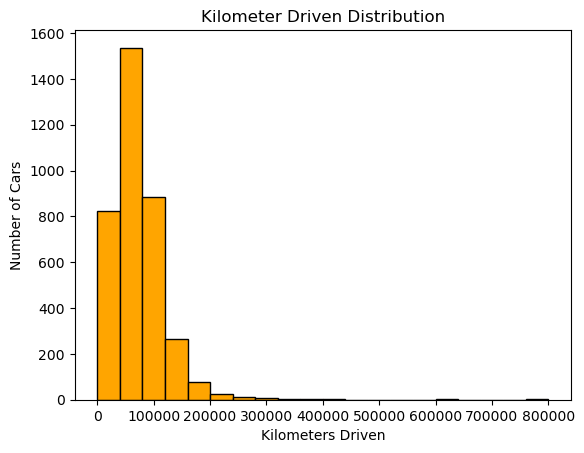

In [43]:
plt.hist(cars['KM Driven'], bins=20, color='orange', edgecolor='black')

plt.xlabel('Kilometers Driven')
plt.ylabel('Number of Cars')
plt.title('Kilometer Driven Distribution')

plt.show()

#### Conclusion:
> + Most used cars have relatively lower kilometers driven, while only a few cars have very high kilometers driven.

### Brand popularity (Univariate Analysis)

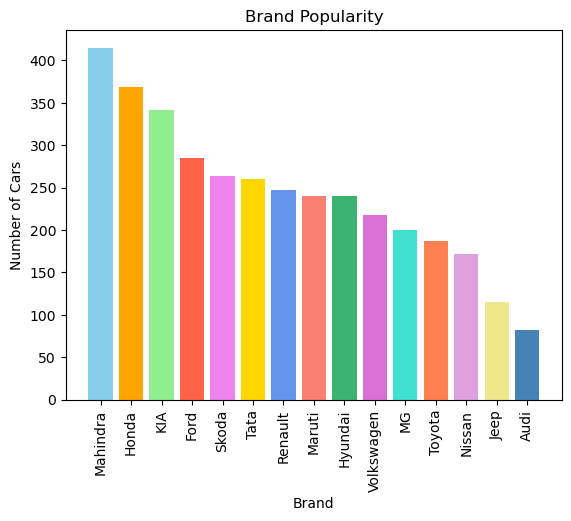

In [46]:
# Brand popularity
brand_popularity = cars['Brand Name'].value_counts()

plt.bar(brand_popularity.index, brand_popularity.values,color = ['skyblue','orange','lightgreen','tomato','violet','gold','cornflowerblue','salmon','mediumseagreen','orchid','turquoise','coral','plum','khaki','steelblue'])

plt.xlabel('Brand')
plt.ylabel('Number of Cars')
plt.title('Brand Popularity')

plt.xticks(rotation=90)
plt.show()

#### Conclusion:
> + Mahindra has the highest number of listings, indicating strong representation of Mahindra vehicles in the Cars24 dataset.

### Price vs KM Driven (Bivariate Analysis)

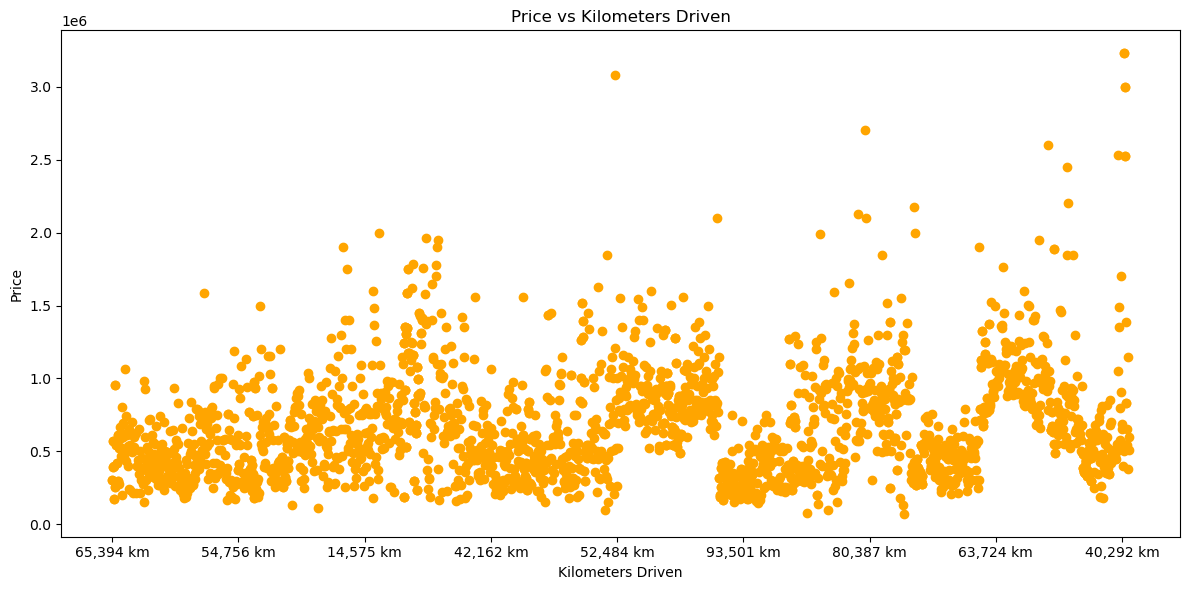

In [53]:
# Price vs KM Driven
plt.figure(figsize=(12, 6))

plt.scatter(price_data['KM Driven'], price_data['Price'],color='orange')

plt.xlabel('Kilometers Driven')
plt.ylabel('Price')
plt.title('Price vs Kilometers Driven')

plt.gca().xaxis.set_major_locator(MaxNLocator(10))

plt.tight_layout()
plt.show()

#### Conclusion:
> + Generally, cars with higher kilometers driven tend to have lower prices, although other factors also influence price.

### Price vs Year (Bivariate Analysis)

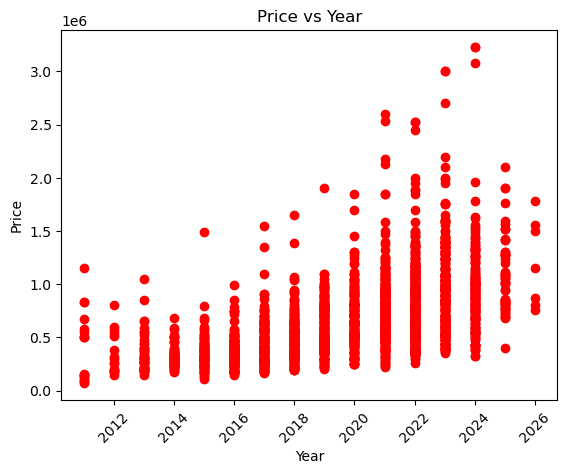

In [54]:
# Price vs Year
plt.scatter(cars['Year'], cars['Price'],color='red')
plt.xlabel('Year')
plt.ylabel('Price')
plt.title('Price vs Year')
plt.xticks(rotation=45)
plt.show()

#### Conclusion:
> + Newer cars generally tend to have higher prices, while older cars are more likely to have lower prices. However, the price varies considerably across different years.

### Brand and Fuel Type (Bivariate Analysis)

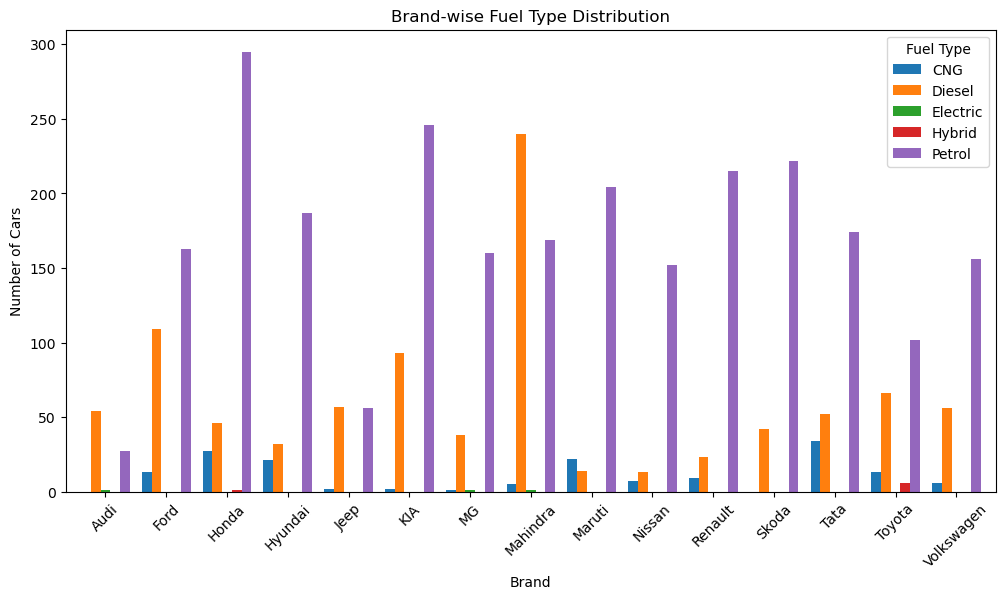

In [49]:
# Brand and Fuel Type
brand_fuel = pd.crosstab(cars['Brand Name'], cars['Fuel Type'])

brand_fuel.plot(kind='bar',figsize=(12, 6),width=0.8)

plt.xlabel('Brand')
plt.ylabel('Number of Cars')
plt.title('Brand-wise Fuel Type Distribution')
plt.xticks(rotation=45)
plt.legend(title='Fuel Type')
plt.show()

#### Conclusion:
> + Petrol cars have the highest number of listings across most brands, while Electric and Hybrid cars have relatively fewer listings. Diesel cars also have a significant presence for some brands, particularly Mahindra and Ford.

### Price vs KM Driven vs Transmission Type (Multivariate Analysis)

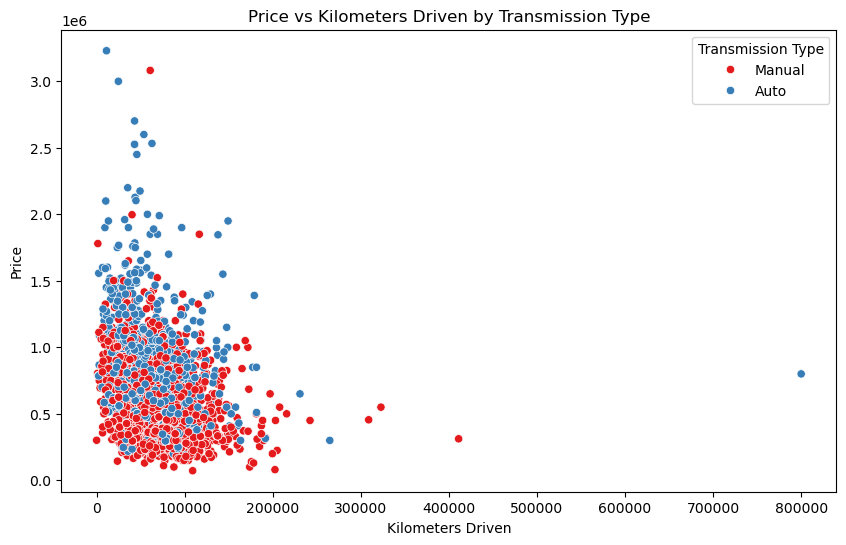

In [58]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=cars,
    x='KM Driven',
    y='Price',
    hue='Transmission Type',
    palette='Set1'
)

plt.xlabel('Kilometers Driven')
plt.ylabel('Price')
plt.title('Price vs Kilometers Driven by Transmission Type')
plt.show()


#### Conclusion
> + Lower kilometers driven generally tend to be associated with higher used-car prices. Manual cars are more concentrated in the lower price range, while automatic cars are more frequently seen at higher price levels.

### Key Business Insights
1. **City**: Used-car prices vary significantly across cities. 
2. **Brand**: Premium brands generally have higher average prices. 
3. **Fuel**: Petrol cars dominate the used-car market. 
4. **Transmission**: Manual cars have more listings than automatic cars. 
5. **Ownership**: 1st-owner cars are most commonly listed. 
6. **Mileage**: Lower-kilometer cars generally have higher prices. 
7. **Brand Demand**: Mahindra has the highest number of listings. 
8. **Age**: Newer cars generally command higher prices. 
9. **Fuel by Brand**: Petrol dominates most brands, while diesel is strong for Mahindra and Ford. 


### Business Recommendations
1. Buyers looking for lower prices can compare cars across cities and brands.
2. Cars with lower kilometers driven can command higher prices.
3. Sellers can use brand, vehicle age and kilometers driven when benchmarking prices.
4. Cars24 can analyze city-wise and brand-wise pricing patterns to improve inventory decisions.
5. Cars24 can focus on high-demand brands and fuel types while maintaining a balanced inventory across cities.